# EDA 05 · Dates and seasonality

**Part I · Raw tables** · part of the 10-notebook EDA series in `workshops/w1/eda/` (index in `README.md`).

**Question.** Does time (registration, transaction and expiry dates) carry information worth encoding as features?

**Data.** Raw files converted to parquet in `workshops/data/parquet/`. The target is the labelled March cohort `train_v2` (970,960 users, 9.0 % churn).

**How to read it.** Plots go from registration dates to transaction dates to membership-expiry dates.

In [ ]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

# Paths resolve from the w1 folder, whether the notebook runs from workshops/w1 or workshops/w1/eda.
W1_DIR = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
DATA_DIR = W1_DIR.parent / "data"      # workshops/data: raw .csv.7z archives
PARQUET_DIR = DATA_DIR / "parquet"     # created once by notebook 01 (or by w1_data_preprocessing)

sns.set()
warnings.filterwarnings("ignore")

PCTS = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 98, 99, 99.5, 99.99, 99.999, 100]


def tabla_percentiles(serie):
    return pd.DataFrame(np.percentile(serie, PCTS), index=PCTS, columns=["valor"])

### Setup carried over from the previous notebooks

The cells below recreate the tables this notebook needs (same code as in the notebooks where they were first analysed; outputs omitted).

In [ ]:
# members_v3.parquet; member.csv and member_v2.csv were replaced by the competition sponsors
member_data = pl.read_parquet(PARQUET_DIR / "members_v3.parquet").to_pandas()
member_data["registration_init_time"] = pd.to_datetime(
    member_data["registration_init_time"].astype(str), format="%Y%m%d")

In [ ]:
# transactions_v2.parquet; both transaction files are used in preprocessing
transaction_data = pl.read_parquet(PARQUET_DIR / "transactions_v2.parquet").to_pandas()
for col in ("transaction_date", "membership_expire_date"):
    transaction_data[col] = pd.to_datetime(
        transaction_data[col].astype(str), format="%Y%m%d")

### Analysis

## 5. Dates

*Let's do some date and time plots.*

![Time](https://i.imgur.com/xuo6LM8.png)

Date and time plots are very interesting.

**Note:** the plots below are for registration.

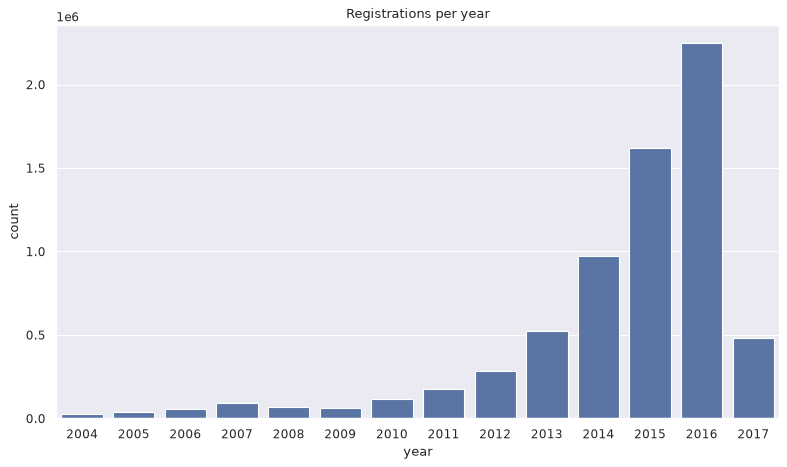

In [61]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=member_data["registration_init_time"].dt.year)
plt.title("Registrations per year")
plt.xlabel("year")
plt.ylabel("count")
plt.tight_layout()
plt.show()

An exponential growth is visible. Since we do not have complete data for 2017, we cannot comment on that part.

### Plot between count and registration month

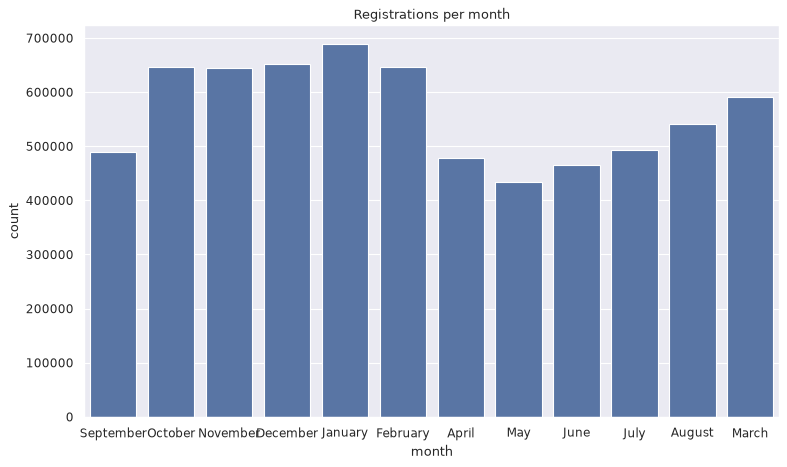

In [62]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=member_data["registration_init_time"].dt.month_name())
plt.title("Registrations per month")
plt.xlabel("month")
plt.ylabel("count")
plt.tight_layout()
plt.show()

People tend to register in the later months, i.e. at the end and start of the year.

### Plot between count and day of week

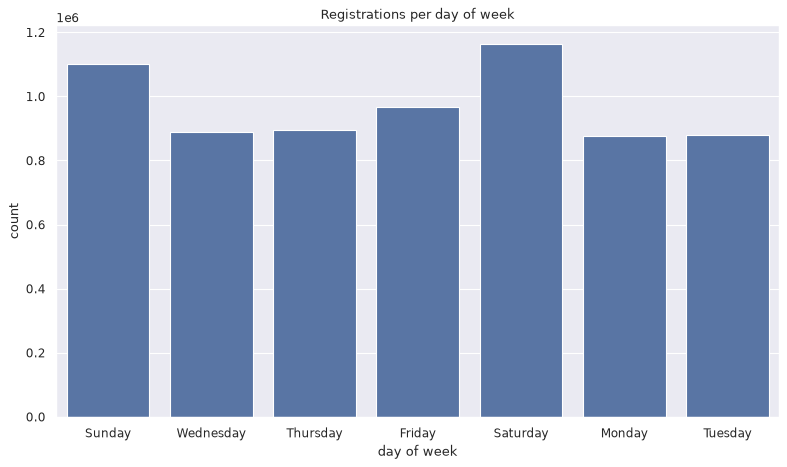

In [63]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=member_data["registration_init_time"].dt.day_name())
plt.title("Registrations per day of week")
plt.xlabel("day of week")
plt.ylabel("count")
plt.tight_layout()
plt.show()

In the initial years growth is slow, but later it increases very fast, with a dip in the last year. More people register on weekends (Saturday and Sunday). May, June and July have fewer registrations.

**Note:** the plots below are for transactions.

### Plot between count and transaction date, year-wise

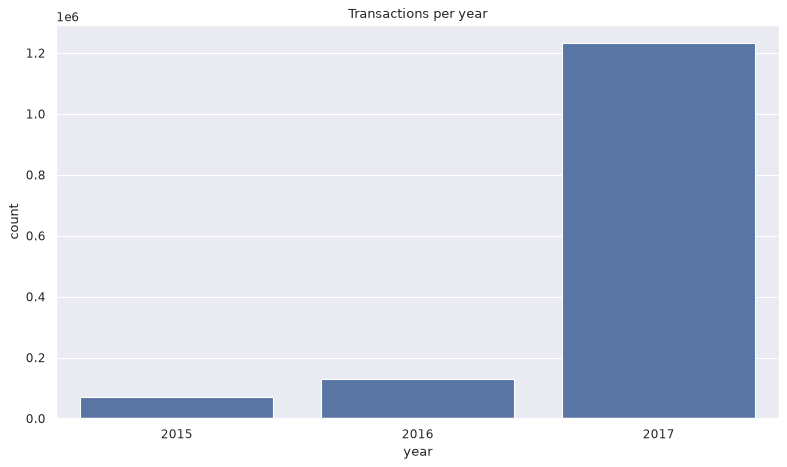

In [64]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=transaction_data["transaction_date"].dt.year)
plt.title("Transactions per year")
plt.xlabel("year")
plt.ylabel("count")
plt.tight_layout()
plt.show()

Since most people use a monthly subscription and we are given 2017 data, this graph is expected.

### Counts vs month of transaction date

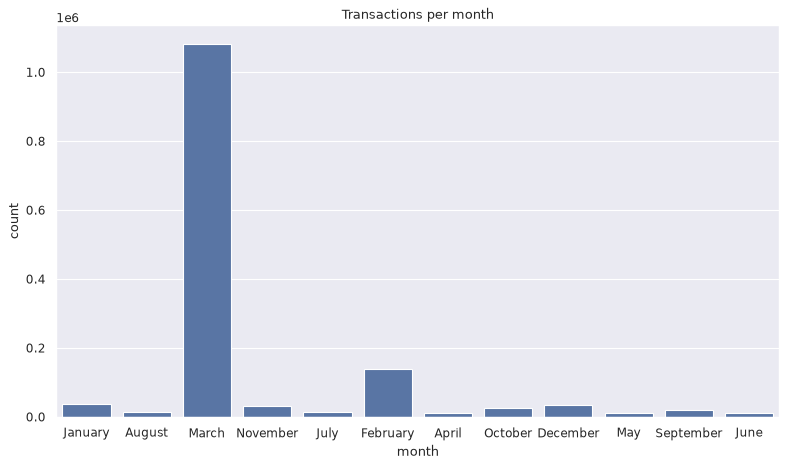

In [65]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=transaction_data["transaction_date"].dt.month_name())
plt.title("Transactions per month")
plt.xlabel("month")
plt.ylabel("count")
plt.tight_layout()
plt.show()

March data is unusually high because we are seeing March data. The plot changes if both transaction files are included.

### Plot between count and transaction date, day of week

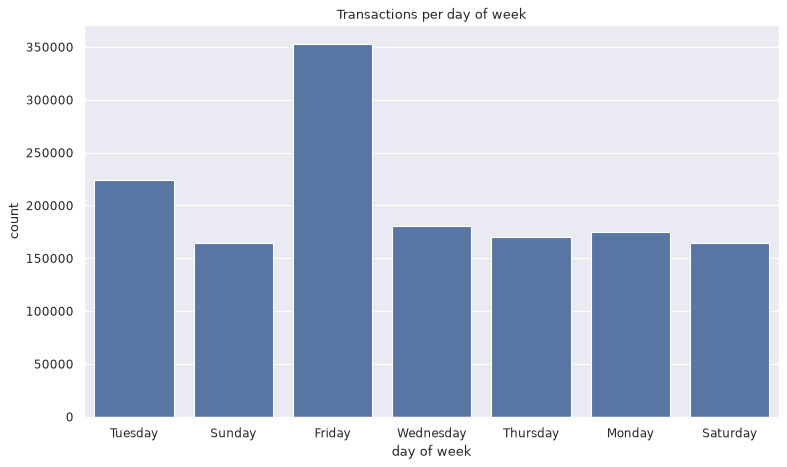

In [66]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=transaction_data["transaction_date"].dt.day_name())
plt.title("Transactions per day of week")
plt.xlabel("day of week")
plt.ylabel("count")
plt.tight_layout()
plt.show()

Most transactions happen in March, then February. Friday has the most transactions, and the number increases year by year.

**Note:** the plots below are for membership expiration date.

In [67]:
transaction_data["membership_expire_date"].dt.year.value_counts()

membership_expire_date
2017    1354731
2018      66549
2019       6735
2020       2074
2021        604
2022        143
2023         41
2024         32
2027         32
2026         20
2025         20
2016         11
2028         10
2036          1
2034          1
2030          1
2032          1
2033          1
2035          1
2031          1
Name: count, dtype: int64

In [68]:
tabla_percentiles(transaction_data["membership_expire_date"].dt.year)

,valor
0.000,2016.0
10.000,2017.0
20.000,2017.0
30.000,2017.0
40.000,2017.0
50.000,2017.0
60.000,2017.0
70.000,2017.0
80.000,2017.0
90.000,2017.0


Some people have an expiration date in 2018 or later. They are long-term users and have a low risk of churning.

### Plot between count and membership expire date, year-wise

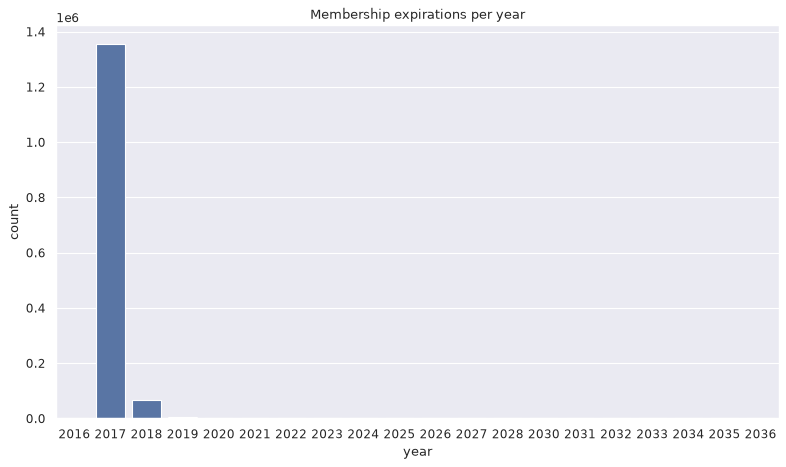

In [69]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=transaction_data["membership_expire_date"].dt.year)
plt.title("Membership expirations per year")
plt.xlabel("year")
plt.ylabel("count")
plt.tight_layout()
plt.show()

This plot is consistent with people taking monthly subscriptions, so their expiration date is in the same year.

In [70]:
transaction_data["membership_expire_date"].dt.month_name().value_counts()

membership_expire_date
April        1037972
May           142927
March          57106
June           39078
July           27782
August         26938
September      25030
October        18034
November       14913
January        14268
February       13532
December       13429
Name: count, dtype: int64

Most subscriptions end in April because this data is from March.

### Count and month of membership expire date

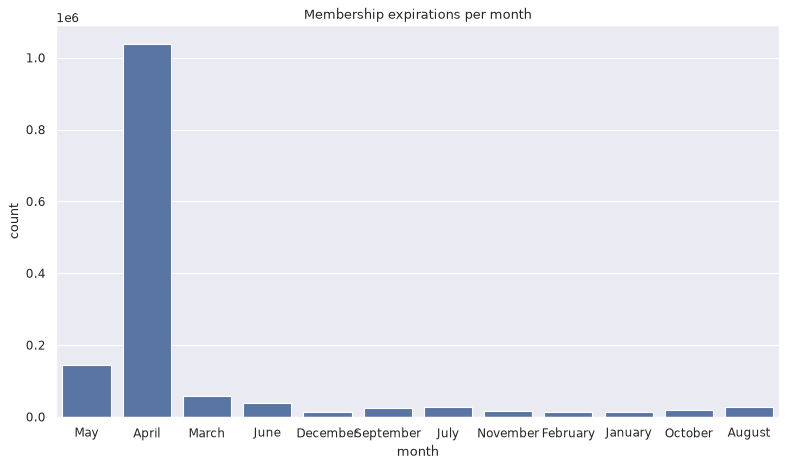

In [71]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=transaction_data["membership_expire_date"].dt.month_name())
plt.title("Membership expirations per month")
plt.xlabel("month")
plt.ylabel("count")
plt.tight_layout()
plt.show()

Since cancelling is not counted as churn, people whose subscription ends after April have a low risk of churning.

### Plot between count and membership expire date, day of week

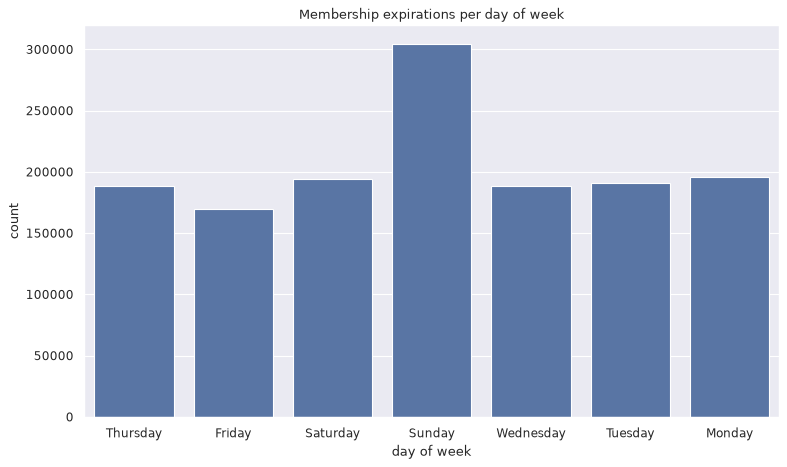

In [72]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=transaction_data["membership_expire_date"].dt.day_name())
plt.title("Membership expirations per day of week")
plt.xlabel("day of week")
plt.ylabel("count")
plt.tight_layout()
plt.show()

The expiration date is consistent with the transaction data; most customers transact within the month. Most subscriptions end within the same year, which shows people do not invest in long-term subscriptions. Sunday is the most likely day for a subscription to end.

### Plot between count and month of transaction

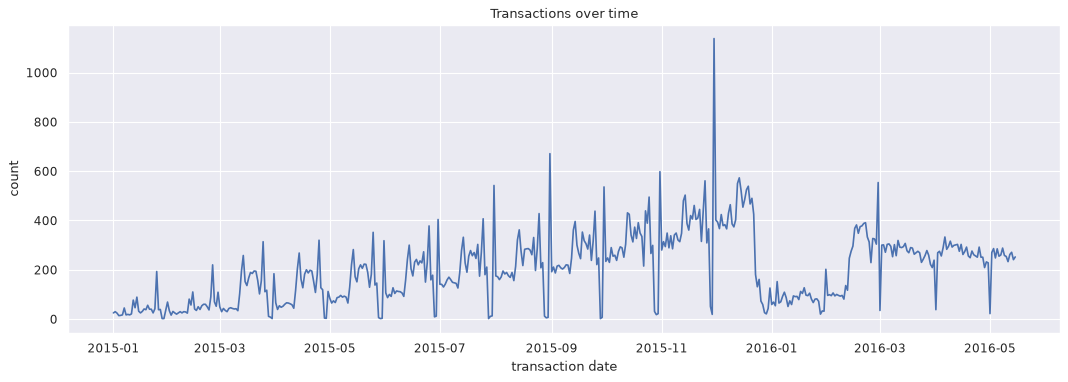

In [73]:
figure(num=None, figsize=(16, 5), dpi=80, facecolor="w", edgecolor="k")
plt.plot(transaction_data["transaction_date"].value_counts().sort_index()[:500])
plt.title("Transactions over time")
plt.xlabel("transaction date")
plt.ylabel("count")
plt.show()

There is a repeating pattern that grows with the year. The growth shows the company's business is increasing, and the repeating pattern shows customer behaviour. The graph below shows the same monthly pattern for the membership expiration date.

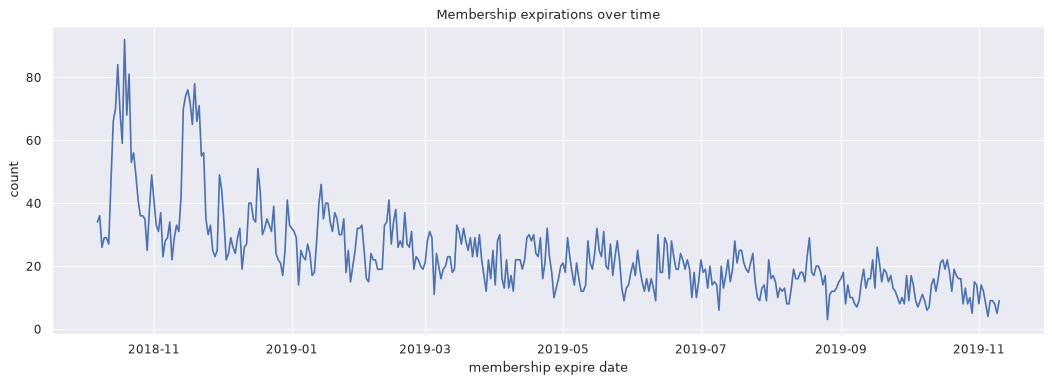

In [74]:
figure(num=None, figsize=(16, 5), dpi=80, facecolor="w", edgecolor="k")
plt.plot(transaction_data["membership_expire_date"].value_counts().sort_index()[600:1000])
plt.title("Membership expirations over time")
plt.xlabel("membership expire date")
plt.ylabel("count")
plt.show()

**Dates.**

- Registrations grow exponentially by year, there are fewer between May and July, and more on weekends.
- Transactions and expirations follow a monthly cycle that grows over time, which is the 30-day renewal cycle.
- Memberships that expire in 2018 or later belong to long-term users, with low churn risk.
- Conclusion: time carries information and must be turned into features (month, day of week, days to expiration).

---
**Previous:** `04_user_logs.ipynb` · **Next:** `06_bivariate_raw.ipynb`